In [2]:

# Cell 1 — Locate HF Lung V1 within the project data directory

from pathlib import Path

PROJECT_ROOT = Path("/Users/vs/Sem 5/Respiratory-Disease-Classification")
DATA_ROOT = PROJECT_ROOT / "data" / "raw"

print("Project root exists:", PROJECT_ROOT.exists())
print("Raw data root exists:", DATA_ROOT.exists())

print("\n========== RAW DATA ROOTS ==========")
if DATA_ROOT.exists():
    for path in sorted(DATA_ROOT.iterdir()):
        kind = "DIR " if path.is_dir() else "FILE"
        print(f"{kind} {path.name}")

print("\n========== POSSIBLE HF LUNG V1 LOCATIONS ==========")
matches = []

if DATA_ROOT.exists():
    for path in DATA_ROOT.rglob("*"):
        if path.is_dir():
            name = path.name.casefold().replace("_", " ").replace("-", " ")
            if "lung" in name or name in {"hf", "hf lung v1"}:
                matches.append(path)

if matches:
    for path in matches:
        print(path)
else:
    print("No likely HF Lung V1 directory found under data/raw.")

print(
    "\nThis is a directory-name search only. It does not assume that any "
    "matching folder is the correct dataset."
)


Project root exists: True
Raw data root exists: True

========== RAW DATA ROOTS ==========
FILE .DS_Store
DIR  BRACETS
DIR  Fraiwan
DIR  HF Lung V1
DIR  ICBHI

========== POSSIBLE HF LUNG V1 LOCATIONS ==========
/Users/vs/Sem 5/Respiratory-Disease-Classification/data/raw/HF Lung V1
/Users/vs/Sem 5/Respiratory-Disease-Classification/data/raw/HF Lung V1/HF_Lung_V1-master

This is a directory-name search only. It does not assume that any matching folder is the correct dataset.


In [3]:

from pathlib import Path
from collections import Counter

HF_ROOT = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "HF Lung V1"
    / "HF_Lung_V1-master"
)

assert HF_ROOT.exists(), f"Dataset directory not found: {HF_ROOT}"

files = [
    p for p in HF_ROOT.rglob("*")
    if p.is_file()
    and not any(
        part.startswith(".")
        for part in p.relative_to(HF_ROOT).parts
    )
]

print("========== HF LUNG V1 AUDIT ==========")
print("Dataset root:", HF_ROOT)
print("Total files:", len(files))

print("\n========== FILE EXTENSIONS ==========")
for ext, count in Counter(
    p.suffix.lower() or "[no extension]" for p in files
).most_common():
    print(f"{ext}: {count}")

print("\n========== TOP-LEVEL CONTENTS ==========")
for p in sorted(HF_ROOT.iterdir()):
    kind = "DIR " if p.is_dir() else "FILE"
    print(f"{kind} {p.name}")

print("\n========== FIRST 100 FILES ==========")
for p in sorted(files)[:100]:
    print(
        f"{p.relative_to(HF_ROOT)} "
        f"| {p.stat().st_size / 1024:.1f} KB"
    )


========== HF LUNG V1 AUDIT ==========
Dataset root: /Users/vs/Sem 5/Respiratory-Disease-Classification/data/raw/HF Lung V1/HF_Lung_V1-master
Total files: 19533

========== FILE EXTENSIONS ==========
.wav: 9765
.txt: 9765
[no extension]: 2
.md: 1

========== TOP-LEVEL CONTENTS ==========
FILE .DS_Store
DIR  Dataset
FILE Disclaimer
FILE LICENSE
FILE README.md

========== FIRST 100 FILES ==========
Dataset/test/steth_20190801_09_46_05.wav | 117.2 KB
Dataset/test/steth_20190801_09_46_05_label.txt | 0.3 KB
Dataset/test/steth_20190801_09_46_26.wav | 117.2 KB
Dataset/test/steth_20190801_09_46_26_label.txt | 0.4 KB
Dataset/test/steth_20190801_09_46_51.wav | 117.2 KB
Dataset/test/steth_20190801_09_46_51_label.txt | 0.3 KB
Dataset/test/steth_20190801_09_47_36.wav | 117.2 KB
Dataset/test/steth_20190801_09_47_36_label.txt | 0.4 KB
Dataset/test/steth_20190801_09_47_58.wav | 117.2 KB
Dataset/test/steth_20190801_09_47_58_label.txt | 0.3 KB
Dataset/test/steth_20190801_09_48_31.wav | 117.2 KB
Dataset/

In [4]:

# Cell 3 — Read HF Lung V1 documentation and inspect labels

from pathlib import Path

# 1. Read repository documentation
print("=" * 70)
print("README.md")
print("=" * 70)

readme_path = HF_ROOT / "README.md"

if readme_path.exists():
    print(readme_path.read_text(encoding="utf-8", errors="replace")[:15000])
else:
    print("README.md not found.")

# 2. Identify dataset subdirectories
dataset_dir = HF_ROOT / "Dataset"

print("\n" + "=" * 70)
print("DATASET SUBDIRECTORIES")
print("=" * 70)

for path in sorted(dataset_dir.iterdir()):
    if path.is_dir():
        wav_count = sum(1 for _ in path.glob("*.wav"))
        txt_count = sum(
            1 for p in path.glob("*.txt")
            if p.name.endswith("_label.txt")
        )
        print(
            f"{path.name}: "
            f"{wav_count} WAV files, {txt_count} label files"
        )

# 3. Inspect representative label files
print("\n" + "=" * 70)
print("SAMPLE LABEL FILES")
print("=" * 70)

label_files = sorted(dataset_dir.rglob("*_label.txt"))

print("Total label files:", len(label_files))

for label_path in label_files[:8]:
    print(f"\nFile: {label_path.relative_to(HF_ROOT)}")

    content = label_path.read_text(
        encoding="utf-8",
        errors="replace"
    ).strip()

    print(content[:2000] if content else "[EMPTY LABEL FILE]")

# 4. Count empty labels
empty_labels = [
    p for p in label_files
    if not p.read_text(
        encoding="utf-8",
        errors="replace"
    ).strip()
]

print("\n" + "=" * 70)
print("LABEL FILE COMPLETENESS")
print("=" * 70)
print("Empty label files:", len(empty_labels))
print("Non-empty label files:", len(label_files) - len(empty_labels))


README.md
# HF_Lung_V1

This repository contains an open access lung sound database used for developing automated inhalation, exhalation, and adventitious sounds detection algorithms. 

The lung sound recordings come from two sources. The first source was a database used in a datathon in Taiwan Smart Emergency and Critical Care (TSECC), 2020, under the license of Creative Commons Attribution 4.0 (CC BY 4.0), provided by the Taiwan Society of Emergency and Critical Care Medicine (TSECCM). Lung sound recordings in the TSECC database were acquired from 261 patients. 

The second source was sound recordings acquired from 18 residents of a respiratory care ward (RCW) or a respiratory care center (RCC) in Northern Taiwan between August 2018 and October 2019. The recordings were approved by the Research Ethics Review Committee of Far Eastern Memorial Hospital (case number: 107052-F). Written informed consent was obtained from the 18 patients.

We have used the database to train and benchmark 

In [5]:

# Cell 4 — Full annotation and recording-group audit
# Read-only: does not modify audio, labels, or existing models.

import re
from collections import Counter
import pandas as pd

dataset_dir = HF_ROOT / "Dataset"

label_files = sorted(dataset_dir.rglob("*_label.txt"))

records = []
event_counts = Counter()
malformed_lines = []
empty_labels = []
missing_audio = []

for label_path in label_files:
    audio_path = label_path.with_name(
        label_path.name.removesuffix("_label.txt") + ".wav"
    )

    if not audio_path.exists():
        missing_audio.append(str(audio_path.relative_to(HF_ROOT)))

    content = label_path.read_text(
        encoding="utf-8", errors="replace"
    ).strip()

    if not content:
        empty_labels.append(
            str(label_path.relative_to(HF_ROOT))
        )

    valid_events = 0
    codes_in_file = set()

    for line_number, line in enumerate(content.splitlines(), start=1):
        parts = line.split()

        if len(parts) != 3:
            malformed_lines.append(
                (str(label_path.relative_to(HF_ROOT)),
                 line_number, line)
            )
            continue

        code, start_text, end_text = parts

        try:
            start = pd.to_timedelta(start_text).total_seconds()
            end = pd.to_timedelta(end_text).total_seconds()
        except (ValueError, TypeError):
            malformed_lines.append(
                (str(label_path.relative_to(HF_ROOT)),
                 line_number, line)
            )
            continue

        if start < 0 or end <= start:
            malformed_lines.append(
                (str(label_path.relative_to(HF_ROOT)),
                 line_number, line)
            )
            continue

        event_counts[code] += 1
        codes_in_file.add(code)
        valid_events += 1

    audio_name = audio_path.name
    prefix = (
        "steth" if audio_name.startswith("steth_")
        else "trunc" if audio_name.startswith("trunc_")
        else "other"
    )

    # The README describes dates as de-identified.
    match = re.match(
        r"^(?:steth_(\d{8})_|trunc_(\d{4}-\d{2}-\d{2})-)",
        audio_name
    )
    date_group = match.group(1) or match.group(2) if match else None

    records.append({
        "label_path": str(label_path.relative_to(HF_ROOT)),
        "audio_path": str(audio_path.relative_to(HF_ROOT)),
        "partition": label_path.relative_to(dataset_dir).parts[0],
        "prefix": prefix,
        "date_group": date_group,
        "valid_event_lines": valid_events,
        "event_codes": ",".join(sorted(codes_in_file)),
        "empty_label": not bool(content),
        "audio_exists": audio_path.exists(),
    })

audit_df = pd.DataFrame(records)

print("=" * 65)
print("ANNOTATION CODE COUNTS")
print("=" * 65)
print(pd.DataFrame(
    event_counts.items(), columns=["code", "event_count"]
).sort_values("event_count", ascending=False).to_string(index=False))

print("\n" + "=" * 65)
print("LABEL FILE AUDIT")
print("=" * 65)
print("Label files:", len(audit_df))
print("Empty label files:", len(empty_labels))
print("Missing matching audio files:", len(missing_audio))
print("Malformed or invalid annotation lines:", len(malformed_lines))

print("\n" + "=" * 65)
print("PARTITION SUMMARY")
print("=" * 65)
print(audit_df.groupby("partition").agg(
    files=("label_path", "count"),
    empty_labels=("empty_label", "sum"),
    recordings_without_audio=("audio_exists",
                               lambda s: (~s).sum()),
    total_event_lines=("valid_event_lines", "sum"),
).to_string())

print("\n" + "=" * 65)
print("RECORDING PREFIX SUMMARY")
print("=" * 65)
print(audit_df.groupby("prefix").agg(
    files=("audio_path", "count"),
    distinct_date_groups=("date_group", "nunique"),
    empty_labels=("empty_label", "sum"),
).to_string())

print("\n" + "=" * 65)
print("RECORDINGS PER DATE GROUP")
print("=" * 65)
date_counts = (
    audit_df.dropna(subset=["date_group"])
    .groupby(["partition", "date_group"])
    .size()
    .rename("recordings")
    .reset_index()
)

print("Distinct partition/date groups:", len(date_counts))
print("Groups with multiple recordings:",
      int((date_counts["recordings"] > 1).sum()))
print("\nLargest groups:")
print(date_counts.sort_values(
    "recordings", ascending=False
).head(15).to_string(index=False))

print("\n" + "=" * 65)
print("SAMPLE EMPTY LABEL FILES")
print("=" * 65)
for path in empty_labels[:20]:
    print(path)

print("\n" + "=" * 65)
print("SAMPLE MALFORMED LINES")
print("=" * 65)
for item in malformed_lines[:20]:
    print(item)

# Retain audit_df for subsequent notebook cells.



ANNOTATION CODE COUNTS
   code  event_count
      I        34095
      E        18349
      D        15606
 Wheeze         8457
Rhonchi         4740
Stridor          686

LABEL FILE AUDIT
Label files: 9765
Empty label files: 58
Missing matching audio files: 0
Malformed or invalid annotation lines: 0

PARTITION SUMMARY
           files  empty_labels  recordings_without_audio  total_event_lines
partition                                                                  
test        1956             4                         0              13851
train       7809            54                         0              68082

RECORDING PREFIX SUMMARY
        files  distinct_date_groups  empty_labels
prefix                                           
steth    4504                   157             6
trunc    5261                    14            52

RECORDINGS PER DATE GROUP
Distinct partition/date groups: 171
Groups with multiple recordings: 165

Largest groups:
partition date_group  recordings


In [6]:

# Cell 5 — Audio format, duration and date-overlap audit
# Read-only. Does not resample, normalize or overwrite recordings.

import numpy as np
import pandas as pd
import soundfile as sf
from pathlib import Path

audio_files = sorted(dataset_dir.rglob("*.wav"))

audio_rows = []
read_errors = []

for audio_path in audio_files:
    relative_path = audio_path.relative_to(dataset_dir)
    partition = relative_path.parts[0]
    filename = audio_path.name

    try:
        info = sf.info(str(audio_path))

        date_group = None

        # Date from Littmann stethoscope filenames
        if filename.startswith("steth_"):
            date_group = filename[6:14]

        # Date from HF_Type-1 filenames
        elif filename.startswith("trunc_"):
            date_group = filename[6:16]

        audio_rows.append({
            "filename": filename,
            "relative_path": str(relative_path),
            "partition": partition,
            "date_group": date_group,
            "sample_rate": info.samplerate,
            "channels": info.channels,
            "frames": info.frames,
            "duration_seconds": info.duration,
            "subtype": info.subtype,
        })

    except Exception as exc:
        read_errors.append({
            "file": str(relative_path),
            "error": str(exc)
        })

audio_df = pd.DataFrame(audio_rows)

print("=" * 65)
print("AUDIO READABILITY")
print("=" * 65)
print("WAV files discovered:", len(audio_files))
print("Files inspected successfully:", len(audio_df))
print("Read errors:", len(read_errors))

print("\n" + "=" * 65)
print("SAMPLE RATE DISTRIBUTION")
print("=" * 65)
print(audio_df["sample_rate"].value_counts().sort_index())

print("\n" + "=" * 65)
print("CHANNEL DISTRIBUTION")
print("=" * 65)
print(audio_df["channels"].value_counts().sort_index())

print("\n" + "=" * 65)
print("DURATION SUMMARY (SECONDS)")
print("=" * 65)
print(audio_df["duration_seconds"].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
).round(3))

print("\n" + "=" * 65)
print("FORMAT SUMMARY BY PREFIX")
print("=" * 65)
audio_df["prefix"] = audio_df["filename"].str.split("_").str[0]

print(audio_df.groupby("prefix").agg(
    files=("filename", "count"),
    sample_rates=("sample_rate", "nunique"),
    channel_counts=("channels", "nunique"),
    median_duration=("duration_seconds", "median"),
    min_duration=("duration_seconds", "min"),
    max_duration=("duration_seconds", "max"),
).round(3))

print("\n" + "=" * 65)
print("DATE OVERLAP BETWEEN TRAIN AND TEST")
print("=" * 65)

date_sets = {
    split: set(
        audio_df.loc[
            audio_df["partition"] == split, "date_group"
        ].dropna()
    )
    for split in ["train", "test"]
}

shared_dates = date_sets["train"] & date_sets["test"]

print("Distinct train dates:", len(date_sets["train"]))
print("Distinct test dates:", len(date_sets["test"]))
print("Dates shared across train and test:", len(shared_dates))
print("Shared dates:", sorted(shared_dates)[:30])

print("\n" + "=" * 65)
print("READ ERRORS")
print("=" * 65)
for error in read_errors[:10]:
    print(error)

# Retain audio_df for subsequent audit cells.


AUDIO READABILITY
WAV files discovered: 9765
Files inspected successfully: 9765
Read errors: 0

SAMPLE RATE DISTRIBUTION
sample_rate
4000    9765
Name: count, dtype: int64

CHANNEL DISTRIBUTION
channels
1    9765
Name: count, dtype: int64

DURATION SUMMARY (SECONDS)
count    9765.0
mean       15.0
std         0.0
min        15.0
5%         15.0
25%        15.0
50%        15.0
75%        15.0
95%        15.0
max        15.0
Name: duration_seconds, dtype: float64

FORMAT SUMMARY BY PREFIX
        files  sample_rates  channel_counts  median_duration  min_duration  \
prefix                                                                       
steth    4504             1               1             15.0          15.0   
trunc    5261             1               1             15.0          15.0   

        max_duration  
prefix                
steth           15.0  
trunc           15.0  

DATE OVERLAP BETWEEN TRAIN AND TEST
Distinct train dates: 130
Distinct test dates: 41
Dates shared acr

In [7]:

# Cell 6 — Validate event timing and annotation intervals
# Read-only: no files are modified.

from collections import Counter
import numpy as np
import pandas as pd

event_rows = []
empty_label_rows = []

for label_path in sorted(dataset_dir.rglob("*_label.txt")):
    audio_path = label_path.with_name(
        label_path.name.removesuffix("_label.txt") + ".wav"
    )

    content = label_path.read_text(
        encoding="utf-8", errors="replace"
    ).strip()

    if not content:
        empty_label_rows.append({
            "partition": label_path.relative_to(dataset_dir).parts[0],
            "filename": label_path.name,
            "audio_filename": audio_path.name,
        })
        continue

    intervals = []

    for line_number, line in enumerate(content.splitlines(), start=1):
        parts = line.split()
        if len(parts) != 3:
            continue

        code, start_text, end_text = parts

        try:
            start = pd.to_timedelta(start_text).total_seconds()
            end = pd.to_timedelta(end_text).total_seconds()
        except (ValueError, TypeError):
            continue

        intervals.append((code, start, end, line_number))

    # Check interval overlap and bounds within each label file.
    ordered = sorted(intervals, key=lambda x: (x[1], x[2]))

    for i, (code, start, end, line_number) in enumerate(ordered):
        event_rows.append({
            "partition": label_path.relative_to(dataset_dir).parts[0],
            "audio_filename": audio_path.name,
            "code": code,
            "start": start,
            "end": end,
            "duration": end - start,
            "line_number": line_number,
            "outside_recording": start < 0 or end > 15.0,
            "invalid_duration": end <= start,
            "overlaps_next": (
                i + 1 < len(ordered)
                and ordered[i + 1][1] < end
            ),
        })

events_df = pd.DataFrame(event_rows)
empty_df = pd.DataFrame(empty_label_rows)

print("=" * 65)
print("EVENT INTERVAL VALIDATION")
print("=" * 65)
print("Non-empty event intervals:", len(events_df))
print("Intervals outside 0–15 seconds:",
      int(events_df["outside_recording"].sum()))
print("Intervals with invalid duration:",
      int(events_df["invalid_duration"].sum()))
print("Intervals overlapping the next annotation:",
      int(events_df["overlaps_next"].sum()))

print("\n" + "=" * 65)
print("EVENT DURATION BY CODE")
print("=" * 65)
print(events_df.groupby("code")["duration"].agg(
    ["count", "median", "mean", "min", "max"]
).round(4).to_string())

print("\n" + "=" * 65)
print("EMPTY LABELS BY PREFIX AND PARTITION")
print("=" * 65)
if not empty_df.empty:
    empty_df["prefix"] = (
        empty_df["audio_filename"].str.split("_").str[0]
    )
    print(pd.crosstab(
        empty_df["partition"], empty_df["prefix"]
    ).to_string())

print("\n" + "=" * 65)
print("EXAMPLES OF EMPTY LABELS")
print("=" * 65)
print(empty_df.head(15).to_string(index=False))

print("\n" + "=" * 65)
print("ANNOTATIONS PER RECORDING")
print("=" * 65)
print(events_df.groupby("audio_filename").size().describe().round(2))


EVENT INTERVAL VALIDATION
Non-empty event intervals: 81933
Intervals outside 0–15 seconds: 0
Intervals with invalid duration: 0
Intervals overlapping the next annotation: 29074

EVENT DURATION BY CODE
         count  median    mean    min    max
code                                        
D        15606  0.8180  0.8876  0.012  7.139
E        18349  0.8340  0.9576  0.001  5.936
I        34095  0.9020  0.9294  0.001  7.139
Rhonchi   4740  0.7600  0.7845  0.029  3.897
Stridor    686  0.7675  0.8270  0.091  2.315
Wheeze    8457  0.7220  0.8495  0.014  6.604

EMPTY LABELS BY PREFIX AND PARTITION
prefix     steth  trunc
partition              
test           4      0
train          2     52

EXAMPLES OF EMPTY LABELS
partition                                  filename                      audio_filename prefix
     test         steth_20190802_09_05_00_label.txt         steth_20190802_09_05_00.wav  steth
     test         steth_20190809_07_23_19_label.txt         steth_20190809_07_23_19.wav  

In [8]:

# Cell 7 — Investigate overlapping annotation types
from itertools import combinations
from collections import Counter
import pandas as pd

print("=" * 70)
print("OVERLAPPING ANNOTATION PAIR AUDIT")
print("=" * 70)

required_cols = {"partition", "audio_filename", "code", "start", "end"}
missing_cols = required_cols - set(events_df.columns)

if missing_cols:
    raise ValueError(f"events_df is missing columns: {missing_cols}")

# Convert times to numeric seconds if necessary.
overlap_df = events_df.copy()
for col in ["start", "end"]:
    if pd.api.types.is_timedelta64_dtype(overlap_df[col]):
        overlap_df[col] = overlap_df[col].dt.total_seconds()
    else:
        overlap_df[col] = pd.to_numeric(overlap_df[col], errors="raise")

pair_counts = Counter()
same_code_overlaps = 0
cross_code_overlaps = 0
overlap_examples = []

# Compare annotations only within the same recording.
for (partition, filename), group in overlap_df.groupby(
    ["partition", "audio_filename"], sort=False
):
    group = group.sort_values(["start", "end"]).reset_index(drop=True)
    records = group.to_dict("records")

    for i, a in enumerate(records):
        # Later intervals cannot overlap once their start >= a.end.
        for b in records[i + 1:]:
            if b["start"] >= a["end"]:
                break

            overlap_seconds = min(a["end"], b["end"]) - max(
                a["start"], b["start"]
            )

            if overlap_seconds > 0:
                code_a, code_b = str(a["code"]), str(b["code"])
                pair = tuple(sorted([code_a, code_b]))
                pair_counts[pair] += 1

                if code_a == code_b:
                    same_code_overlaps += 1
                else:
                    cross_code_overlaps += 1

                if len(overlap_examples) < 15:
                    overlap_examples.append({
                        "partition": partition,
                        "audio_filename": filename,
                        "code_1": code_a,
                        "start_1": a["start"],
                        "end_1": a["end"],
                        "code_2": code_b,
                        "start_2": b["start"],
                        "end_2": b["end"],
                        "overlap_seconds": round(overlap_seconds, 4),
                    })

pair_df = pd.DataFrame([
    {"code_pair": f"{a} + {b}", "overlap_count": count}
    for (a, b), count in pair_counts.most_common()
])

print(f"Total overlapping interval pairs: {sum(pair_counts.values()):,}")
print(f"Same-code overlaps: {same_code_overlaps:,}")
print(f"Different-code overlaps: {cross_code_overlaps:,}")

print("\nMOST COMMON OVERLAPPING CODE PAIRS")
display(pair_df.head(20))

print("\nEXAMPLE OVERLAPS")
display(pd.DataFrame(overlap_examples))

# Count how many recordings contain at least one overlap.
recordings_with_overlap = set()
for row in overlap_examples:
    recordings_with_overlap.add(
        (row["partition"], row["audio_filename"])
    )

print(
    "\nNote: the example list is capped at 15, so its recording count "
    "is not the total number of recordings with overlaps."
)


OVERLAPPING ANNOTATION PAIR AUDIT


Total overlapping interval pairs: 31,171
Same-code overlaps: 72
Different-code overlaps: 31,099

MOST COMMON OVERLAPPING CODE PAIRS


,code_pair,overlap_count
0,D + I,9837
1,D + E,6470
2,I + Wheeze,4528
3,I + Rhonchi,2795
4,E + Wheeze,2490
5,E + I,2230
6,E + Rhonchi,1803
7,I + Stridor,364
8,D + Wheeze,209
9,E + Stridor,176



EXAMPLE OVERLAPS


,partition,audio_filename,code_1,start_1,end_1,code_2,start_2,end_2,overlap_seconds
0,test,steth_20190801_09_46_05.wav,I,1.120,1.937,D,1.120,1.937,0.817
1,test,steth_20190801_09_46_05.wav,I,3.340,4.157,D,3.340,4.157,0.817
2,test,steth_20190801_09_46_05.wav,I,5.674,6.491,D,5.674,6.491,0.817
3,test,steth_20190801_09_46_05.wav,I,7.855,8.805,D,7.855,8.805,0.950
4,test,steth_20190801_09_46_05.wav,I,10.018,10.968,D,10.018,10.968,0.950
5,test,steth_20190801_09_46_05.wav,I,12.105,13.055,D,12.105,13.055,0.950
6,test,steth_20190801_09_46_26.wav,I,0.000,0.856,D,0.000,0.856,0.856
7,test,steth_20190801_09_46_26.wav,I,1.992,2.848,D,1.992,2.848,0.856
8,test,steth_20190801_09_46_26.wav,I,4.382,5.238,D,4.382,5.238,0.856
9,test,steth_20190801_09_46_26.wav,I,6.640,7.496,D,6.640,7.496,0.856



Note: the example list is capped at 15, so its recording count is not the total number of recordings with overlaps.


In [9]:

# Cell 8 — Verify raw annotation semantics and exact interval matches

from pathlib import Path
import pandas as pd

# Inspect several real annotation files.
sample_files = [
    ("test", "steth_20190801_09_46_05_label.txt"),
    ("test", "steth_20190801_09_46_26_label.txt"),
    ("train", "trunc_2019-05-07-14-29-34-L2_1_label.txt"),
]

print("=" * 70)
print("RAW LABEL FILE EXAMPLES")
print("=" * 70)

for partition, filename in sample_files:
    path = dataset_dir / partition / filename
    print(f"\n--- {partition}/{filename} ---")
    if path.exists():
        print(path.read_text(encoding="utf-8", errors="replace")[:2500])
    else:
        print("File not found:", path)

# Quantify exact-boundary matches between D and other codes.
df = events_df.copy()

for col in ["start", "end"]:
    if pd.api.types.is_timedelta64_dtype(df[col]):
        df[col] = df[col].dt.total_seconds()
    else:
        df[col] = pd.to_numeric(df[col], errors="raise")

# Use rounded millisecond boundaries to avoid floating-point artifacts.
df["start_key"] = df["start"].round(3)
df["end_key"] = df["end"].round(3)

key_cols = ["partition", "audio_filename", "start_key", "end_key"]

codes_by_interval = (
    df.groupby(key_cols)["code"]
      .agg(lambda s: set(s.astype(str)))
      .reset_index(name="codes")
)

def has_pair(codes, a, b):
    return a in codes and b in codes

exact_summary = []
for a, b in [("D", "I"), ("D", "E"), ("I", "E")]:
    matched = codes_by_interval["codes"].apply(
        lambda codes: has_pair(codes, a, b)
    )
    exact_summary.append({
        "pair": f"{a} + {b}",
        "exact_shared_intervals": int(matched.sum()),
    })

print("\n" + "=" * 70)
print("EXACT SHARED INTERVAL BOUNDARIES")
print("=" * 70)
display(pd.DataFrame(exact_summary))

print("\nExamples of intervals carrying multiple codes:")
display(
    codes_by_interval[
        codes_by_interval["codes"].apply(lambda x: len(x) > 1)
    ].head(20)
)

# Search the dataset README for annotation definitions.
readme_candidates = [
    HF_ROOT / "README.md",
    dataset_dir / "README.md",
]

print("\n" + "=" * 70)
print("README ANNOTATION DEFINITIONS")
print("=" * 70)

keywords = [
    "discontinuous", "continuous", "crackle", "wheeze",
    "stridor", "rhonchi", "annotation", "label", "inhalation",
    "exhalation", "code", "D:"
]

found_readme = False

for readme_path in readme_candidates:
    if readme_path.exists():
        found_readme = True
        lines = readme_path.read_text(
            encoding="utf-8", errors="replace"
        ).splitlines()

        print(f"\nREADME: {readme_path}")
        for i, line in enumerate(lines):
            if any(k in line.lower() for k in keywords):
                start = max(0, i - 1)
                end = min(len(lines), i + 2)
                print(f"\nLines {start + 1}-{end}:")
                for j in range(start, end):
                    print(f"{j + 1}: {lines[j]}")

if not found_readme:
    print("README not found at the expected paths.")


RAW LABEL FILE EXAMPLES

--- test/steth_20190801_09_46_05_label.txt ---
I 00:00:01.120 00:00:01.937
D 00:00:01.120 00:00:01.937
I 00:00:03.340 00:00:04.157
D 00:00:03.340 00:00:04.157
I 00:00:05.674 00:00:06.491
D 00:00:05.674 00:00:06.491
I 00:00:07.855 00:00:08.805
D 00:00:07.855 00:00:08.805
I 00:00:10.018 00:00:10.968
D 00:00:10.018 00:00:10.968
I 00:00:12.105 00:00:13.055
D 00:00:12.105 00:00:13.055


--- test/steth_20190801_09_46_26_label.txt ---
I 00:00:00.000 00:00:00.856
D 00:00:00.000 00:00:00.856
I 00:00:01.992 00:00:02.848
D 00:00:01.992 00:00:02.848
I 00:00:04.382 00:00:05.238
D 00:00:04.382 00:00:05.238
I 00:00:06.640 00:00:07.496
D 00:00:06.640 00:00:07.496
I 00:00:08.803 00:00:09.659
D 00:00:08.803 00:00:09.659
I 00:00:10.966 00:00:11.822
D 00:00:10.966 00:00:11.822
I 00:00:13.129 00:00:13.985
D 00:00:13.129 00:00:13.985


--- train/trunc_2019-05-07-14-29-34-L2_1_label.txt ---


EXACT SHARED INTERVAL BOUNDARIES


,pair,exact_shared_intervals
0,D + I,8070
1,D + E,5201
2,I + E,10



Examples of intervals carrying multiple codes:


,partition,audio_filename,start_key,end_key,codes
0,test,steth_20190801_09_46_05.wav,1.120,1.937,"{I, D}"
1,test,steth_20190801_09_46_05.wav,3.340,4.157,"{I, D}"
2,test,steth_20190801_09_46_05.wav,5.674,6.491,"{I, D}"
3,test,steth_20190801_09_46_05.wav,7.855,8.805,"{I, D}"
4,test,steth_20190801_09_46_05.wav,10.018,10.968,"{I, D}"
5,test,steth_20190801_09_46_05.wav,12.105,13.055,"{I, D}"
6,test,steth_20190801_09_46_26.wav,0.000,0.856,"{I, D}"
7,test,steth_20190801_09_46_26.wav,1.992,2.848,"{I, D}"
8,test,steth_20190801_09_46_26.wav,4.382,5.238,"{I, D}"
9,test,steth_20190801_09_46_26.wav,6.640,7.496,"{I, D}"



README ANNOTATION DEFINITIONS

README: /Users/vs/Sem 5/Respiratory-Disease-Classification/data/raw/HF Lung V1/HF_Lung_V1-master/README.md

Lines 2-4:
2: 
3: This repository contains an open access lung sound database used for developing automated inhalation, exhalation, and adventitious sounds detection algorithms. 
4: 

Lines 11-13:
11: Unzip the files to get two folders, train and test, which are the training dataset and test dataset used in a study.
12: Inside the folders you can find 15-second-long lung sound recordings and the corresponding labels, including 9765 15-second audio files, 34,095 inhalation labels, 18,349 exhalation labels, 13,883 continuous adventitious sound labels (including 8,457 wheeze labels, 686 stridor labels and 4,740 rhonchi labels) and 15,606 discontinuous adventitious sound (all are crackles) labels in total.
13: 

Lines 24-26:
24: 
25: The labels are saved in Text (.txt) format. The filename of the labels has the same beginning as the filename of corresp

In [10]:

# Cell 9 — Inventory documentation and scripts related to label generation

from pathlib import Path

repo_root = HF_ROOT

interesting_extensions = {
    ".md", ".txt", ".py", ".ipynb", ".csv", ".json",
    ".yaml", ".yml", ".xml", ".pdf"
}

print("=" * 70)
print("HF LUNG V1 REPOSITORY FILE INVENTORY")
print("=" * 70)

for path in sorted(repo_root.rglob("*")):
    if not path.is_file():
        continue

    # Exclude audio and annotation files from this documentation inventory.
    if path.suffix.lower() in interesting_extensions:
        relative = path.relative_to(repo_root)
        print(relative)

print("\n" + "=" * 70)
print("SEARCH FOR ANNOTATION CONVENTIONS")
print("=" * 70)

search_terms = [
    "discontinuous", "crackle", "annotation", "annotator",
    "ground truth", "label", "inhalation", "exhalation",
    "overlap", "wheeze", "rhonchi", "stridor"
]

text_extensions = {".md", ".txt", ".py", ".csv", ".json", ".yaml", ".yml"}

for path in sorted(repo_root.rglob("*")):
    if not path.is_file() or path.suffix.lower() not in text_extensions:
        continue

    try:
        content = path.read_text(encoding="utf-8", errors="ignore")
    except Exception:
        continue

    matching_lines = [
        (line_number, line.strip())
        for line_number, line in enumerate(content.splitlines(), start=1)
        if any(term in line.lower() for term in search_terms)
    ]

    if matching_lines:
        print(f"\nFILE: {path.relative_to(repo_root)}")
        for line_number, line in matching_lines[:20]:
            print(f"{line_number}: {line[:250]}")


HF LUNG V1 REPOSITORY FILE INVENTORY
Dataset/test/steth_20190801_09_46_05_label.txt
Dataset/test/steth_20190801_09_46_26_label.txt
Dataset/test/steth_20190801_09_46_51_label.txt
Dataset/test/steth_20190801_09_47_36_label.txt
Dataset/test/steth_20190801_09_47_58_label.txt
Dataset/test/steth_20190801_09_48_31_label.txt
Dataset/test/steth_20190801_09_49_03_label.txt
Dataset/test/steth_20190801_09_51_07_label.txt
Dataset/test/steth_20190801_09_52_21_label.txt
Dataset/test/steth_20190801_09_52_41_label.txt
Dataset/test/steth_20190801_09_53_09_label.txt
Dataset/test/steth_20190801_09_53_45_label.txt
Dataset/test/steth_20190801_09_54_19_label.txt
Dataset/test/steth_20190801_09_54_44_label.txt
Dataset/test/steth_20190801_09_57_02_label.txt
Dataset/test/steth_20190801_09_57_25_label.txt
Dataset/test/steth_20190801_09_58_08_label.txt
Dataset/test/steth_20190801_09_58_34_label.txt
Dataset/test/steth_20190801_09_59_00_label.txt
Dataset/test/steth_20190801_09_59_27_label.txt
Dataset/test/steth_2019

Partition: test
Audio: steth_20190801_09_46_05.wav
Sample rate: 4000
Duration (seconds): 15.0

Original label file:
I 00:00:01.120 00:00:01.937
D 00:00:01.120 00:00:01.937
I 00:00:03.340 00:00:04.157
D 00:00:03.340 00:00:04.157
I 00:00:05.674 00:00:06.491
D 00:00:05.674 00:00:06.491
I 00:00:07.855 00:00:08.805
D 00:00:07.855 00:00:08.805
I 00:00:10.018 00:00:10.968
D 00:00:10.018 00:00:10.968
I 00:00:12.105 00:00:13.055
D 00:00:12.105 00:00:13.055



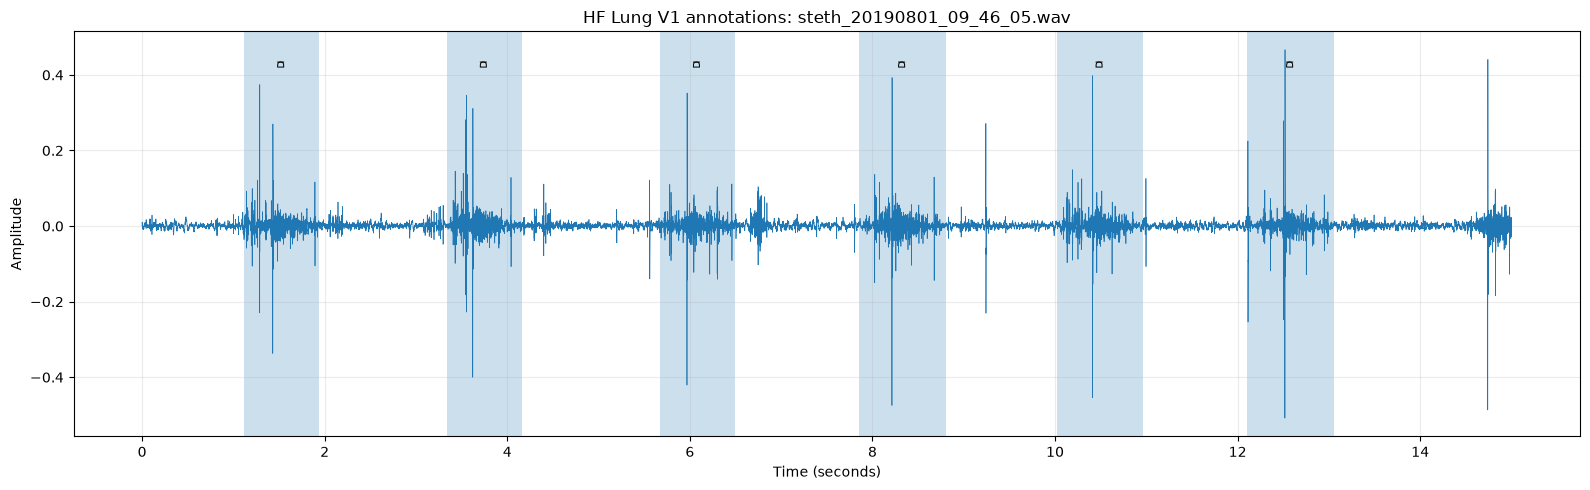

Play the recording:


In [11]:

# Cell 10 — Visual inspection of an annotated HF Lung V1 recording

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from scipy.io import wavfile

# Choose a recording with both I and D annotations.
candidates = (
    events_df[
        (events_df["code"].astype(str).isin(["I", "D"]))
    ]
    .groupby(["partition", "audio_filename"])["code"]
    .agg(lambda s: set(s.astype(str)))
    .reset_index()
)

candidates = candidates[
    candidates["code"].apply(lambda s: {"I", "D"}.issubset(s))
]

if candidates.empty:
    raise ValueError("No recording containing both I and D annotations was found.")

# Prefer the first available candidate for reproducibility.
chosen = candidates.iloc[0]
partition = chosen["partition"]
audio_filename = chosen["audio_filename"]

audio_path = dataset_dir / partition / audio_filename
label_path = dataset_dir / partition / (
    Path(audio_filename).stem + "_label.txt"
)

sample_rate, signal = wavfile.read(audio_path)

# Convert to float for plotting/playback, without changing the stored file.
signal_float = signal.astype(np.float32)
if np.issubdtype(signal.dtype, np.integer):
    signal_float /= max(abs(np.iinfo(signal.dtype).min),
                        np.iinfo(signal.dtype).max)

if signal_float.ndim > 1:
    signal_float = signal_float.mean(axis=1)

time = np.arange(len(signal_float)) / sample_rate

print("Partition:", partition)
print("Audio:", audio_filename)
print("Sample rate:", sample_rate)
print("Duration (seconds):", round(len(signal_float) / sample_rate, 3))
print("\nOriginal label file:")
print(label_path.read_text(encoding="utf-8", errors="replace"))

# Plot waveform and annotate each interval using its original code.
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(time, signal_float, linewidth=0.5)
ax.set_title(f"HF Lung V1 annotations: {audio_filename}")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Amplitude")

recording_events = events_df[
    (events_df["partition"] == partition)
    & (events_df["audio_filename"] == audio_filename)
].copy()

for _, event in recording_events.iterrows():
    start = event["start"]
    end = event["end"]

    if pd.api.types.is_timedelta64_dtype(events_df["start"]):
        start = start.total_seconds()
        end = end.total_seconds()

    start = float(start)
    end = float(end)
    code = str(event["code"])

    ax.axvspan(start, end, alpha=0.12)
    ax.text(
        (start + end) / 2,
        ax.get_ylim()[1] * 0.85,
        code,
        rotation=90,
        ha="center",
        va="top",
        fontsize=7
    )

ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

print("Play the recording:")
display(Audio(signal_float, rate=sample_rate))


Recordings with wheeze/rhonchi/stridor: 3699
Recordings with D but no I/E labels: 2

Adventitious sound | test | steth_20190801_09_52_41.wav
Codes: ['D', 'I', 'Wheeze']
I 00:00:01.329 00:00:02.070
D 00:00:01.329 00:00:02.070
I 00:00:03.681 00:00:04.423
D 00:00:03.681 00:00:04.423
Wheeze 00:00:04.099 00:00:04.328
I 00:00:05.599 00:00:06.357
D 00:00:05.599 00:00:06.357
I 00:00:07.951 00:00:08.880
D 00:00:07.951 00:00:08.880
Wheeze 00:00:08.293 00:00:08.576
I 00:00:09.925 00:00:10.644
D 00:00:09.925 00:00:10.644
I 00:00:12.296 00:00:13.092
D 00:00:12.296 00:00:13.092



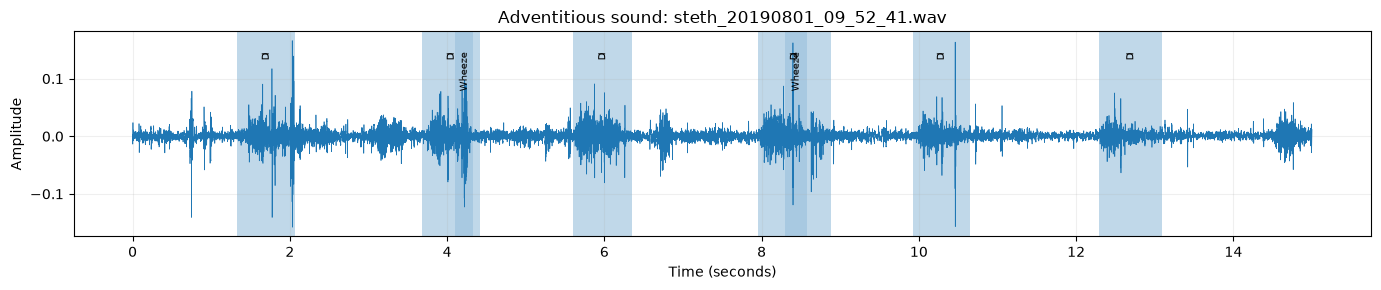


D without I/E | train | trunc_2019-06-23-10-32-54-L8_14.wav
Codes: ['D']
D 00:00:01.408 00:00:02.287



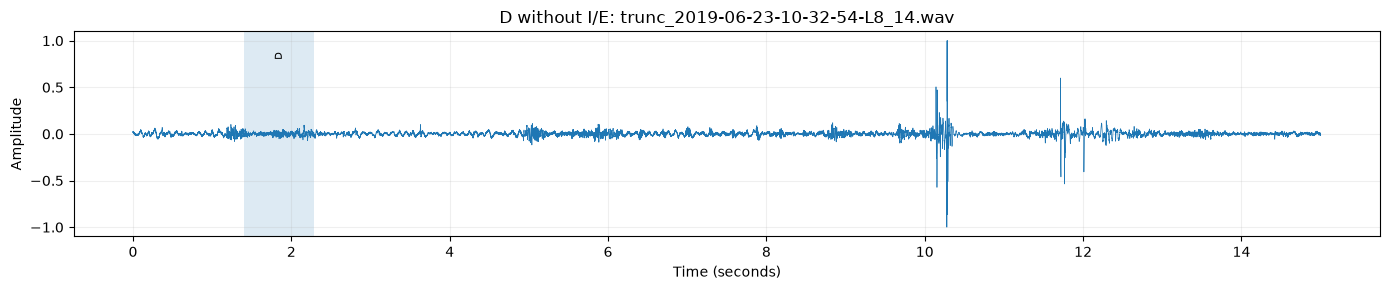

In [12]:

# Cell 11 — Compare different annotation patterns

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.io import wavfile
from IPython.display import Audio, display

df = events_df.copy()

for col in ["start", "end"]:
    if pd.api.types.is_timedelta64_dtype(df[col]):
        df[col] = df[col].dt.total_seconds()
    else:
        df[col] = pd.to_numeric(df[col], errors="raise")

# Build the list of codes present in each recording.
recording_codes = (
    df.groupby(["partition", "audio_filename"])["code"]
      .agg(lambda s: set(s.astype(str)))
      .reset_index(name="codes")
)

# Prefer a recording with adventitious sounds other than D.
abnormal = recording_codes[
    recording_codes["codes"].apply(
        lambda s: bool(s.intersection({"Wheeze", "Rhonchi", "Stridor"}))
    )
]

# Find recordings with D but no I/E annotations.
d_without_phase = recording_codes[
    recording_codes["codes"].apply(
        lambda s: "D" in s and "I" not in s and "E" not in s
    )
]

print("Recordings with wheeze/rhonchi/stridor:", len(abnormal))
print("Recordings with D but no I/E labels:", len(d_without_phase))

selected = []

if not abnormal.empty:
    selected.append(("Adventitious sound", abnormal.iloc[0]))

if not d_without_phase.empty:
    selected.append(("D without I/E", d_without_phase.iloc[0]))

# Include one different recording as a comparison if needed.
if len(selected) < 2:
    other = recording_codes[
        ~recording_codes["audio_filename"].isin(
            [item[1]["audio_filename"] for item in selected]
        )
    ]
    if not other.empty:
        selected.append(("Comparison", other.iloc[0]))

for title, item in selected:
    partition = item["partition"]
    filename = item["audio_filename"]
    audio_path = dataset_dir / partition / filename
    label_path = dataset_dir / partition / (
        Path(filename).stem + "_label.txt"
    )

    sr, signal = wavfile.read(audio_path)
    signal = signal.astype(np.float32)

    if np.issubdtype(wavfile.read(audio_path)[1].dtype, np.integer):
        signal /= max(abs(np.iinfo(wavfile.read(audio_path)[1].dtype).min),
                      np.iinfo(wavfile.read(audio_path)[1].dtype).max)

    if signal.ndim > 1:
        signal = signal.mean(axis=1)

    time = np.arange(len(signal)) / sr

    print("\n" + "=" * 60)
    print(title, "|", partition, "|", filename)
    print("Codes:", sorted(item["codes"]))
    print(label_path.read_text(encoding="utf-8", errors="replace"))

    fig, ax = plt.subplots(figsize=(14, 3))
    ax.plot(time, signal, linewidth=0.5)

    rec_events = df[
        (df["partition"] == partition)
        & (df["audio_filename"] == filename)
    ]

    for _, event in rec_events.iterrows():
        start, end = float(event["start"]), float(event["end"])
        ax.axvspan(start, end, alpha=0.15)
        ax.text((start + end) / 2, ax.get_ylim()[1] * 0.8,
                str(event["code"]), fontsize=7, rotation=90,
                ha="center", va="top")

    ax.set_title(f"{title}: {filename}")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()

    display(Audio(signal, rate=sr))


In [13]:

# Cell 12 — Audit phase and adventitious-sound co-occurrence
import pandas as pd

df = events_df.copy()

for col in ["start", "end"]:
    if pd.api.types.is_timedelta64_dtype(df[col]):
        df[col] = df[col].dt.total_seconds()
    else:
        df[col] = pd.to_numeric(df[col], errors="raise")

# Count annotation codes per recording.
codes_per_recording = (
    df.groupby(["partition", "audio_filename"])["code"]
      .agg(lambda s: set(s.astype(str)))
      .reset_index(name="codes")
)

def count_recordings(predicate):
    return int(codes_per_recording["codes"].apply(predicate).sum())

summary = [
    ("All recordings with non-empty labels", len(codes_per_recording)),
    ("Recordings with I", count_recordings(lambda s: "I" in s)),
    ("Recordings with E", count_recordings(lambda s: "E" in s)),
    ("Recordings with both I and E", count_recordings(
        lambda s: "I" in s and "E" in s
    )),
    ("Recordings with D but no I/E", count_recordings(
        lambda s: "D" in s and "I" not in s and "E" not in s
    )),
    ("Recordings with wheeze/rhonchi/stridor", count_recordings(
        lambda s: bool(s.intersection({"Wheeze", "Rhonchi", "Stridor"}))
    )),
    ("Recordings with adventitious labels but no I/E", count_recordings(
        lambda s: bool(s.intersection(
            {"D", "Wheeze", "Rhonchi", "Stridor"}
        )) and "I" not in s and "E" not in s
    )),
]

display(pd.DataFrame(summary, columns=["Audit", "Recording count"]))

print("\nCode counts by partition:")
display(pd.crosstab(df["code"], df["partition"]))

print("\nRecordings with D but no I/E:")
display(
    codes_per_recording[
        codes_per_recording["codes"].apply(
            lambda s: "D" in s and "I" not in s and "E" not in s
        )
    ].head(20)
)


,Audit,Recording count
0,All recordings with non-empty labels,9707
1,Recordings with I,9445
2,Recordings with E,5543
3,Recordings with both I and E,5489
4,Recordings with D but no I/E,2
5,Recordings with wheeze/rhonchi/stridor,3699
6,Recordings with adventitious labels but no I/E,208



Code counts by partition:


partition,test,train
code,,
D,1812,13794
E,2748,15601
I,6872,27223
Rhonchi,960,3780
Stridor,29,657
Wheeze,1430,7027



Recordings with D but no I/E:


,partition,audio_filename,codes
7431,train,trunc_2019-06-23-10-32-54-L8_14.wav,{D}
9704,train,trunc_2019-07-31-11-20-43-L8_12.wav,{D}


In [14]:

# Cell 13 — Create a read-only event manifest

from pathlib import Path
import pandas as pd
import re

manifest = events_df.copy()

# Standardize annotation times to seconds.
for col in ["start", "end"]:
    if pd.api.types.is_timedelta64_dtype(manifest[col]):
        manifest[col] = manifest[col].dt.total_seconds()
    else:
        manifest[col] = pd.to_numeric(manifest[col], errors="raise")

manifest["audio_path"] = manifest.apply(
    lambda row: str(dataset_dir / row["partition"] / row["audio_filename"]),
    axis=1
)

def extract_date_group(filename):
    # steth_20190801_09_46_05.wav -> 20190801
    m = re.match(r"steth_(\d{8})_", filename)
    if m:
        return m.group(1)

    # trunc_2019-05-07-13-57-26-L8_2.wav -> 2019-05-07
    m = re.match(r"trunc_(\d{4}-\d{2}-\d{2})-", filename)
    if m:
        return m.group(1)

    return None

manifest["prefix"] = manifest["audio_filename"].str.split("_").str[0]
manifest["date_group"] = manifest["audio_filename"].apply(extract_date_group)
manifest["duration_seconds"] = manifest["end"] - manifest["start"]

# Basic integrity checks.
assert manifest["audio_path"].map(lambda p: Path(p).exists()).all()
assert (manifest["start"] >= 0).all()
assert (manifest["end"] <= 15.0).all()
assert (manifest["duration_seconds"] > 0).all()

print("Event rows:", len(manifest))
print("Unique recordings:", manifest["audio_filename"].nunique())
print("Missing date groups:", manifest["date_group"].isna().sum())
print("Train event rows:", (manifest["partition"] == "train").sum())
print("Test event rows:", (manifest["partition"] == "test").sum())

print("\nEvent counts by partition and code:")
display(pd.crosstab(manifest["code"], manifest["partition"]))

print("\nUnique recording counts by partition and code:")
display(
    manifest.groupby(["partition", "code"])["audio_filename"]
    .nunique()
    .unstack(fill_value=0)
)

print("\nTrain date groups:", manifest.loc[
    manifest["partition"] == "train", "date_group"
].nunique())

print("Test date groups:", manifest.loc[
    manifest["partition"] == "test", "date_group"
].nunique())

print("\nDate groups shared between train and test:")
train_dates = set(manifest.loc[
    manifest["partition"] == "train", "date_group"
].dropna())
test_dates = set(manifest.loc[
    manifest["partition"] == "test", "date_group"
].dropna())

print(sorted(train_dates & test_dates))

# Keep the manifest in memory for the next step.
display(manifest.head())


Event rows: 81933
Unique recordings: 9707
Missing date groups: 0
Train event rows: 68082
Test event rows: 13851

Event counts by partition and code:


partition,test,train
code,,
D,1812,13794
E,2748,15601
I,6872,27223
Rhonchi,960,3780
Stridor,29,657
Wheeze,1430,7027



Unique recording counts by partition and code:


code,D,E,I,Rhonchi,Stridor,Wheeze
partition,,,,,,
test,368,950,1935,296,12,405
train,3076,4593,7510,944,253,2253



Train date groups: 130
Test date groups: 41

Date groups shared between train and test:
[]


,partition,audio_filename,code,start,end,duration,line_number,outside_recording,invalid_duration,overlaps_next,audio_path,prefix,date_group,duration_seconds
0,test,steth_20190801_09_46_05.wav,I,1.120,1.937,0.817,1,False,False,True,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,steth,20190801,0.817
1,test,steth_20190801_09_46_05.wav,D,1.120,1.937,0.817,2,False,False,False,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,steth,20190801,0.817
2,test,steth_20190801_09_46_05.wav,I,3.340,4.157,0.817,3,False,False,True,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,steth,20190801,0.817
3,test,steth_20190801_09_46_05.wav,D,3.340,4.157,0.817,4,False,False,False,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,steth,20190801,0.817
4,test,steth_20190801_09_46_05.wav,I,5.674,6.491,0.817,5,False,False,True,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,steth,20190801,0.817


In [15]:

# Cell 14 — Date-grouped train/validation split

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# One row per recording, using only the supplied training partition.
train_manifest = manifest[
    manifest["partition"] == "train"
].copy()

recording_labels = (
    train_manifest.groupby(
        ["date_group", "audio_filename"]
    )["code"]
    .agg(lambda s: set(s.astype(str)))
    .reset_index()
)

# Confirm date groups are valid and all recordings have a date.
assert recording_labels["date_group"].notna().all()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        recording_labels,
        groups=recording_labels["date_group"]
    )
)

train_recordings = set(
    recording_labels.iloc[train_idx]["audio_filename"]
)
val_recordings = set(
    recording_labels.iloc[val_idx]["audio_filename"]
)

train_dates = set(
    recording_labels.iloc[train_idx]["date_group"]
)
val_dates = set(
    recording_labels.iloc[val_idx]["date_group"]
)

# Expand recording membership back to all event rows.
hf_train_events = train_manifest[
    train_manifest["audio_filename"].isin(train_recordings)
].copy()

hf_val_events = train_manifest[
    train_manifest["audio_filename"].isin(val_recordings)
].copy()

assert train_dates.isdisjoint(val_dates)
assert set(hf_train_events["audio_filename"]).isdisjoint(
    set(hf_val_events["audio_filename"])
)

print("=" * 70)
print("DATE-GROUPED SPLIT SUMMARY")
print("=" * 70)

print("Training recordings:", len(train_recordings))
print("Validation recordings:", len(val_recordings))
print("Training dates:", len(train_dates))
print("Validation dates:", len(val_dates))
print("Shared dates:", len(train_dates & val_dates))

print("\nRecording counts by label:")
label_rows = []

for code in sorted(train_manifest["code"].astype(str).unique()):
    train_count = hf_train_events.loc[
        hf_train_events["code"].astype(str) == code,
        "audio_filename"
    ].nunique()

    val_count = hf_val_events.loc[
        hf_val_events["code"].astype(str) == code,
        "audio_filename"
    ].nunique()

    label_rows.append({
        "code": code,
        "train_recordings": train_count,
        "validation_recordings": val_count
    })

display(pd.DataFrame(label_rows))

print("\nEvent interval counts:")
display(pd.DataFrame([
    {
        "split": "train",
        "event_intervals": len(hf_train_events),
        "recordings": hf_train_events["audio_filename"].nunique()
    },
    {
        "split": "validation",
        "event_intervals": len(hf_val_events),
        "recordings": hf_val_events["audio_filename"].nunique()
    }
]))

# Keep the recording lists for the next step.
print("\nTraining and validation date sets are disjoint.")


DATE-GROUPED SPLIT SUMMARY
Training recordings: 6038
Validation recordings: 1717
Training dates: 104
Validation dates: 26
Shared dates: 0

Recording counts by label:


,code,train_recordings,validation_recordings
0,D,2467,609
1,E,3774,819
2,I,5843,1667
3,Rhonchi,626,318
4,Stridor,212,41
5,Wheeze,1630,623



Event interval counts:


,split,event_intervals,recordings
0,train,52819,6038
1,validation,15263,1717



Training and validation date sets are disjoint.


In [16]:

# Cell 15 — Check readiness for the lightweight baseline

import importlib.util
from pathlib import Path

required_packages = [
    "numpy",
    "pandas",
    "scipy",
    "sklearn",
    "soundfile",
]

package_status = {
    package: importlib.util.find_spec(package) is not None
    for package in required_packages
}

print("PACKAGE AVAILABILITY")
for package, available in package_status.items():
    print(f"{package}: {'available' if available else 'MISSING'}")

assert all(package_status.values()), (
    "Install the missing packages before continuing."
)

# Check split objects and the untouched original test partition.
assert "hf_train_events" in globals()
assert "hf_val_events" in globals()
assert "manifest" in globals()

assert set(hf_train_events["date_group"]).isdisjoint(
    set(hf_val_events["date_group"])
)

test_events = manifest[manifest["partition"] == "test"].copy()

print("\nSPLIT READINESS")
print("Training recordings:", hf_train_events["audio_filename"].nunique())
print("Validation recordings:", hf_val_events["audio_filename"].nunique())
print("Test recordings:", test_events["audio_filename"].nunique())
print("Training date groups:", hf_train_events["date_group"].nunique())
print("Validation date groups:", hf_val_events["date_group"].nunique())
print("Test date groups:", test_events["date_group"].nunique())

print("\nTarget classes:")
print(["D", "Wheeze", "Rhonchi", "Stridor"])

print("\nAudio root exists:", dataset_dir.exists())
print("Training audio exists:", all(
    Path(p).exists() for p in hf_train_events["audio_path"].head(10)
))


PACKAGE AVAILABILITY
numpy: available
pandas: available
scipy: available
sklearn: available
soundfile: available

SPLIT READINESS
Training recordings: 6038
Validation recordings: 1717
Test recordings: 1952
Training date groups: 104
Validation date groups: 26
Test date groups: 41

Target classes:
['D', 'Wheeze', 'Rhonchi', 'Stridor']

Audio root exists: True
Training audio exists: True


In [17]:

# Cell 16 — Define audio windowing and compact features

import numpy as np
import pandas as pd
import soundfile as sf

from scipy.signal import welch
from scipy.fft import rfft, rfftfreq
from scipy.fft import dct

TARGET_SR = 4000
WINDOW_SECONDS = 1.0
HOP_SECONDS = 0.5
WINDOW_SAMPLES = int(TARGET_SR * WINDOW_SECONDS)
HOP_SAMPLES = int(TARGET_SR * HOP_SECONDS)

EVENT_CLASSES = ["D", "Wheeze", "Rhonchi", "Stridor"]

def load_mono_audio(path):
    audio, sr = sf.read(path, dtype="float32", always_2d=False)

    if audio.ndim > 1:
        audio = audio.mean(axis=1)

    if sr != TARGET_SR:
        raise ValueError(
            f"Unexpected sample rate {sr} for {path}; "
            f"expected {TARGET_SR} Hz."
        )

    return audio

def extract_window_features(x, sr=TARGET_SR):
    """Extract a compact, deterministic feature vector from one window."""
    x = np.asarray(x, dtype=np.float32)

    if len(x) != WINDOW_SAMPLES:
        raise ValueError(f"Expected {WINDOW_SAMPLES} samples, got {len(x)}")

    eps = 1e-10
    x_centered = x - np.mean(x)

    # Time-domain features
    rms = np.sqrt(np.mean(x ** 2) + eps)
    std = np.std(x)
    peak = np.max(np.abs(x))
    zcr = np.mean(
        np.signbit(x_centered[1:]) != np.signbit(x_centered[:-1])
    )
    crest_factor = peak / (rms + eps)

    # Power spectrum
    freqs, power = welch(
        x_centered,
        fs=sr,
        nperseg=512,
        noverlap=256,
        scaling="spectrum"
    )
    power = np.maximum(power, 0)
    total_power = np.sum(power) + eps
    spectral_centroid = np.sum(freqs * power) / total_power
    spectral_bandwidth = np.sqrt(
        np.sum(((freqs - spectral_centroid) ** 2) * power)
        / total_power
    )

    cumulative = np.cumsum(power)
    rolloff_idx = np.searchsorted(cumulative, 0.85 * cumulative[-1])
    spectral_rolloff = freqs[min(rolloff_idx, len(freqs) - 1)]

    # Compact log-spectrum cepstral summary (13 coefficients).
    spectrum = np.abs(rfft(x_centered, n=1024))
    log_spectrum = np.log(spectrum + eps)
    mfcc_like = dct(log_spectrum, type=2, norm="ortho")[:13]

    features = {
        "rms": rms,
        "std": std,
        "peak": peak,
        "zcr": zcr,
        "crest_factor": crest_factor,
        "spectral_centroid": spectral_centroid,
        "spectral_bandwidth": spectral_bandwidth,
        "spectral_rolloff_85": spectral_rolloff,
    }

    features.update({
        f"cepstral_{i + 1}": float(value)
        for i, value in enumerate(mfcc_like)
    })

    return features

print("Feature functions defined.")
print("Window length:", WINDOW_SECONDS, "seconds")
print("Hop length:", HOP_SECONDS, "seconds")
print("Samples per window:", WINDOW_SAMPLES)
print("Number of features:", 8 + 13)


Feature functions defined.
Window length: 1.0 seconds
Hop length: 0.5 seconds
Samples per window: 4000
Number of features: 21


In [18]:

# Cell 17 — Extract training-window features and multi-label targets

from pathlib import Path

def build_recording_events(event_df, filename):
    subset = event_df[event_df["audio_filename"] == filename]
    return [
        (str(row.code), float(row.start), float(row.end))
        for row in subset.itertuples()
    ]

def generate_windows(audio):
    # Drop any trailing partial window to keep fixed-size feature inputs.
    for start_sample in range(
        0, len(audio) - WINDOW_SAMPLES + 1, HOP_SAMPLES
    ):
        end_sample = start_sample + WINDOW_SAMPLES
        yield start_sample, end_sample, audio[start_sample:end_sample]

def make_target_vector(start_sec, end_sec, recording_events):
    targets = {}

    for code in EVENT_CLASSES:
        positive = False

        for event_code, event_start, event_end in recording_events:
            if event_code != code:
                continue

            overlap = max(
                0.0,
                min(end_sec, event_end) - max(start_sec, event_start)
            )

            if overlap / WINDOW_SECONDS >= 0.50:
                positive = True
                break

        targets[code] = int(positive)

    return targets

train_recording_names = sorted(
    hf_train_events["audio_filename"].unique()
)

feature_rows = []
target_rows = []
metadata_rows = []
failed_files = []

for i, filename in enumerate(train_recording_names, start=1):
    rows = hf_train_events[
        hf_train_events["audio_filename"] == filename
    ]

    audio_path = Path(rows.iloc[0]["audio_path"])
    try:
        audio = load_mono_audio(audio_path)
        recording_events = build_recording_events(
            hf_train_events, filename
        )

        for start_sample, end_sample, window in generate_windows(audio):
            start_sec = start_sample / TARGET_SR
            end_sec = end_sample / TARGET_SR

            feature_rows.append(extract_window_features(window))
            target_rows.append(
                make_target_vector(
                    start_sec, end_sec, recording_events
                )
            )
            metadata_rows.append({
                "audio_filename": filename,
                "date_group": rows.iloc[0]["date_group"],
                "start_sec": start_sec,
                "end_sec": end_sec,
            })

    except Exception as exc:
        failed_files.append((filename, repr(exc)))

    if i % 500 == 0:
        print(f"Processed {i}/{len(train_recording_names)} recordings")

X_train_raw = pd.DataFrame(feature_rows)
y_train = pd.DataFrame(target_rows)
train_window_metadata = pd.DataFrame(metadata_rows)

print("\nTRAINING WINDOW DATA")
print("Feature matrix:", X_train_raw.shape)
print("Target matrix:", y_train.shape)
print("Metadata:", train_window_metadata.shape)
print("Failed recordings:", len(failed_files))

if failed_files:
    display(pd.DataFrame(
        failed_files, columns=["filename", "error"]
    ).head(20))

print("\nPositive-window counts by target:")
display(y_train.sum().rename("positive_windows").to_frame())

print("\nNegative-window counts by target:")
display((len(y_train) - y_train.sum()).rename("negative_windows").to_frame())

assert len(X_train_raw) == len(y_train) == len(train_window_metadata)
assert list(y_train.columns) == EVENT_CLASSES


Processed 500/6038 recordings
Processed 1000/6038 recordings
Processed 1500/6038 recordings
Processed 2000/6038 recordings
Processed 2500/6038 recordings
Processed 3000/6038 recordings
Processed 3500/6038 recordings
Processed 4000/6038 recordings
Processed 4500/6038 recordings
Processed 5000/6038 recordings
Processed 5500/6038 recordings
Processed 6000/6038 recordings

TRAINING WINDOW DATA
Feature matrix: (175102, 21)
Target matrix: (175102, 4)
Metadata: (175102, 4)
Failed recordings: 0

Positive-window counts by target:


,positive_windows
D,18729
Wheeze,7245
Rhonchi,3635
Stridor,761



Negative-window counts by target:


,negative_windows
D,156373
Wheeze,167857
Rhonchi,171467
Stridor,174341


In [19]:

# Cell 18 — Extract validation-window features and targets

val_recording_names = sorted(
    hf_val_events["audio_filename"].unique()
)

val_feature_rows = []
val_target_rows = []
val_metadata_rows = []
val_failed_files = []

for i, filename in enumerate(val_recording_names, start=1):
    rows = hf_val_events[
        hf_val_events["audio_filename"] == filename
    ]

    audio_path = Path(rows.iloc[0]["audio_path"])

    try:
        audio = load_mono_audio(audio_path)
        recording_events = build_recording_events(
            hf_val_events, filename
        )

        for start_sample, end_sample, window in generate_windows(audio):
            start_sec = start_sample / TARGET_SR
            end_sec = end_sample / TARGET_SR

            val_feature_rows.append(
                extract_window_features(window)
            )

            val_target_rows.append(
                make_target_vector(
                    start_sec,
                    end_sec,
                    recording_events
                )
            )

            val_metadata_rows.append({
                "audio_filename": filename,
                "date_group": rows.iloc[0]["date_group"],
                "start_sec": start_sec,
                "end_sec": end_sec,
            })

    except Exception as exc:
        val_failed_files.append((filename, repr(exc)))

    if i % 250 == 0:
        print(f"Processed {i}/{len(val_recording_names)} validation recordings")

X_val_raw = pd.DataFrame(
    val_feature_rows,
    columns=X_train_raw.columns
)

y_val = pd.DataFrame(
    val_target_rows,
    columns=EVENT_CLASSES
)

val_window_metadata = pd.DataFrame(val_metadata_rows)

print("\nVALIDATION WINDOW DATA")
print("Feature matrix:", X_val_raw.shape)
print("Target matrix:", y_val.shape)
print("Metadata:", val_window_metadata.shape)
print("Failed recordings:", len(val_failed_files))

if val_failed_files:
    display(pd.DataFrame(
        val_failed_files,
        columns=["filename", "error"]
    ).head(20))

print("\nPositive-window counts:")
display(y_val.sum().rename("positive_windows").to_frame())

print("\nPositive-window rates:")
display(
    (100 * y_val.mean())
    .rename("positive_rate_percent")
    .to_frame()
)

assert len(X_val_raw) == len(y_val) == len(val_window_metadata)
assert list(X_val_raw.columns) == list(X_train_raw.columns)
assert list(y_val.columns) == EVENT_CLASSES

assert set(train_window_metadata["date_group"]).isdisjoint(
    set(val_window_metadata["date_group"])
)

print("\nFeature columns match training.")
print("Training/validation date groups are disjoint.")


Processed 250/1717 validation recordings
Processed 500/1717 validation recordings
Processed 750/1717 validation recordings
Processed 1000/1717 validation recordings
Processed 1250/1717 validation recordings
Processed 1500/1717 validation recordings

VALIDATION WINDOW DATA
Feature matrix: (49793, 21)
Target matrix: (49793, 4)
Metadata: (49793, 4)
Failed recordings: 0

Positive-window counts:


,positive_windows
D,4166
Wheeze,3161
Rhonchi,1877
Stridor,229



Positive-window rates:


,positive_rate_percent
D,8.366638
Wheeze,6.348282
Rhonchi,3.769606
Stridor,0.459904



Feature columns match training.
Training/validation date groups are disjoint.


In [20]:

# Cell 19 — Fit multi-label logistic regression baseline

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
)

baseline_models = {}
baseline_probabilities = {}
baseline_results = []

for target in EVENT_CLASSES:
    y_train_target = y_train[target].astype(int)
    y_val_target = y_val[target].astype(int)

    # Guard against a target containing only one class in training.
    if y_train_target.nunique() < 2:
        print(f"Skipping {target}: training target has only one class.")
        continue

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            solver="liblinear",
            random_state=42,
        )),
    ])

    model.fit(X_train_raw, y_train_target)

    probabilities = model.predict_proba(X_val_raw)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    baseline_models[target] = model
    baseline_probabilities[target] = probabilities

    baseline_results.append({
        "target": target,
        "positive_train": int(y_train_target.sum()),
        "positive_validation": int(y_val_target.sum()),
        "precision_at_0.5": precision_score(
            y_val_target, predictions, zero_division=0
        ),
        "recall_at_0.5": recall_score(
            y_val_target, predictions, zero_division=0
        ),
        "f1_at_0.5": f1_score(
            y_val_target, predictions, zero_division=0
        ),
        "average_precision": average_precision_score(
            y_val_target, probabilities
        ),
        "roc_auc": (
            roc_auc_score(y_val_target, probabilities)
            if y_val_target.nunique() == 2
            else np.nan
        ),
    })

baseline_results_df = pd.DataFrame(baseline_results)

print("=" * 70)
print("VALIDATION RESULTS — DEFAULT THRESHOLD 0.5")
print("=" * 70)
display(baseline_results_df.round(4))

print("\nMacro-average F1 at threshold 0.5:",
      round(baseline_results_df["f1_at_0.5"].mean(), 4))
print("Mean average precision:",
      round(baseline_results_df["average_precision"].mean(), 4))


VALIDATION RESULTS — DEFAULT THRESHOLD 0.5


,target,positive_train,positive_validation,precision_at_0.5,recall_at_0.5,f1_at_0.5,average_precision,roc_auc
0,D,18729,4166,0.1520,0.5430,0.2375,0.1501,0.6924
1,Wheeze,7245,3161,0.1171,0.4859,0.1887,0.1101,0.6854
2,Rhonchi,3635,1877,0.0760,0.4976,0.1319,0.0724,0.6999
3,Stridor,761,229,0.0088,0.5983,0.0173,0.0100,0.7105



Macro-average F1 at threshold 0.5: 0.1439
Mean average precision: 0.0857


In [21]:

# Cell 20 — Validation-only threshold selection

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
)

threshold_results = []
selected_thresholds = {}

threshold_grid = np.arange(0.05, 0.951, 0.01)

for target in EVENT_CLASSES:
    y_true = y_val[target].astype(int).to_numpy()
    probabilities = baseline_probabilities[target]

    candidates = []

    for threshold in threshold_grid:
        y_pred = (probabilities >= threshold).astype(int)

        precision = precision_score(
            y_true, y_pred, zero_division=0
        )
        recall = recall_score(
            y_true, y_pred, zero_division=0
        )
        f1 = f1_score(
            y_true, y_pred, zero_division=0
        )

        candidates.append({
            "threshold": float(threshold),
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "predicted_positive_rate": float(y_pred.mean()),
        })

    result = pd.DataFrame(candidates)

    # Select the highest F1; if tied, prefer higher precision.
    best = result.sort_values(
        ["f1", "precision", "threshold"],
        ascending=[False, False, False]
    ).iloc[0]

    selected_thresholds[target] = best["threshold"]

    threshold_results.append({
        "target": target,
        "threshold": best["threshold"],
        "precision": best["precision"],
        "recall": best["recall"],
        "f1": best["f1"],
        "predicted_positive_rate": best["predicted_positive_rate"],
        "average_precision": average_precision_score(
            y_true, probabilities
        ),
    })

threshold_results_df = pd.DataFrame(threshold_results)

print("VALIDATION-OPTIMIZED THRESHOLDS")
display(threshold_results_df.round(4))

print(
    "\nMacro-F1 at selected validation thresholds:",
    round(threshold_results_df["f1"].mean(), 4)
)

print("\nSelected thresholds:")
print(selected_thresholds)


VALIDATION-OPTIMIZED THRESHOLDS


,target,threshold,precision,recall,f1,predicted_positive_rate,average_precision
0,D,0.53,0.1583,0.4875,0.2390,0.2577,0.1501
1,Wheeze,0.50,0.1171,0.4859,0.1887,0.2635,0.1101
2,Rhonchi,0.55,0.0803,0.4529,0.1364,0.2127,0.0724
3,Stridor,0.82,0.0154,0.0742,0.0256,0.0221,0.0100



Macro-F1 at selected validation thresholds: 0.1474

Selected thresholds:
{'D': np.float64(0.5300000000000001), 'Wheeze': np.float64(0.5000000000000001), 'Rhonchi': np.float64(0.55), 'Stridor': np.float64(0.8200000000000002)}


In [22]:

# Cell 21 — Random forest baseline for multi-label sound detection

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
)

rf_models = {}
rf_probabilities = {}
rf_results = []

for target in EVENT_CLASSES:
    y_train_target = y_train[target].astype(int)
    y_val_target = y_val[target].astype(int)

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=18,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42,
    )

    model.fit(X_train_raw, y_train_target)

    probabilities = model.predict_proba(X_val_raw)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    rf_models[target] = model
    rf_probabilities[target] = probabilities

    rf_results.append({
        "target": target,
        "precision_at_0.5": precision_score(
            y_val_target, predictions, zero_division=0
        ),
        "recall_at_0.5": recall_score(
            y_val_target, predictions, zero_division=0
        ),
        "f1_at_0.5": f1_score(
            y_val_target, predictions, zero_division=0
        ),
        "average_precision": average_precision_score(
            y_val_target, probabilities
        ),
        "roc_auc": roc_auc_score(
            y_val_target, probabilities
        ),
    })

rf_results_df = pd.DataFrame(rf_results)

print("=" * 70)
print("RANDOM FOREST — VALIDATION RESULTS")
print("=" * 70)
display(rf_results_df.round(4))

print(
    "\nMacro-F1 at threshold 0.5:",
    round(rf_results_df["f1_at_0.5"].mean(), 4)
)
print(
    "Mean average precision:",
    round(rf_results_df["average_precision"].mean(), 4)
)


RANDOM FOREST — VALIDATION RESULTS


,target,precision_at_0.5,recall_at_0.5,f1_at_0.5,average_precision,roc_auc
0,D,0.1726,0.3752,0.2364,0.1497,0.7208
1,Wheeze,0.1991,0.1784,0.1882,0.1553,0.7052
2,Rhonchi,0.1074,0.1412,0.1220,0.0838,0.7087
3,Stridor,0.0081,0.0087,0.0084,0.0107,0.7337



Macro-F1 at threshold 0.5: 0.1388
Mean average precision: 0.0999
